In [1]:
#Task 2
# Doğrulama loss'unu ve örnekleri ekle. Eğitim sırasında belli aralıklarla
# doğrulama loss'unu ölç ve modelden kısa bir metin ürettir. Train ve val
# loss'u aynı grafikte çiz. (3:23:10 - 3:28:23)

In [2]:
#imports
import json
import matplotlib.pyplot as plt
import tiktoken
from dataclasses import dataclass
import torch
import torch.nn as nn
from torch.nn import functional as F
import math
import time
import numpy as np
import os
from google.colab import drive
torch.manual_seed(1337)
if torch.cuda.is_available():
  torch.cuda.manual_seed(1337)
import inspect
torch.set_float32_matmul_precision('high')
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!nvidia-smi

Sun Nov  8 14:35:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   30C    P0             49W /  400W |       6MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [4]:
class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        #batchwisely k q v projections for all heads
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        #output projection
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1.0
        #regularization
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        #mask
        self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
            .view(1, 1, config.block_size, config.block_size))


    def forward(self, x):
        B, T, C = x.size() #batch size, sequence length, embedding dims

        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim = 2)
        k = k.view(B,T, self.n_head, C // self.n_head).transpose(1,2) #B, T, nh, hs to B, nh, T, hs
        q = q.view(B,T, self.n_head, C // self.n_head).transpose(1,2) #B, T, nh, hs to B, nh, T, hs
        v = v.view(B,T, self.n_head, C // self.n_head).transpose(1,2) #B, T, nh, hs to B, nh, T, hs
        #attention
        #att = (q @ k.transpose(-2,-1)) * (1.0 / math.sqrt(k.size(-1)))
        #att = att.masked_fill(self.bias[:,:,:T,:T] == 0, float("-inf"))
        #att = F.softmax(att, dim=-1)

        #y = att @ v #(B, nh, T, T) x (B, nh, T, hs) = (B, nh, T, hs)
        #Flash attention

        y = F.scaled_dot_product_attention(q,k,v, is_causal=True)

        #taking all head outputs side by side
        y = y.transpose(1,2).contiguous().view(B,T,C)
        #output projection
        y = self.c_proj(y)
        return y

In [5]:
class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate = "tanh") #nonlinearity
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1.0
    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


In [6]:
class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

In [7]:
@dataclass
class GPTConfig:
    block_size: int= 1024
    vocab_size: int = 50257
    n_layer: int= 12
    n_head: int= 12
    n_embd: int= 768

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config

        self.transformer = nn.ModuleDict(dict(
                    wte = nn.Embedding(config.vocab_size, config.n_embd), #token embds
                    wpe = nn.Embedding(config.block_size, config.n_embd), #positional embds
                    h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), #hidden blocks
                    ln_f = nn.LayerNorm(config.n_embd),)) #final layernorm

        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False) #final classifier

        #weight tying // sharing
        self.transformer.wte.weight = self.lm_head.weight

        #param init
        self.apply(self._init_weights)

    #initialization parameter setting
    def _init_weights(self, module):
        #linear layer, embd -> N(0,0.02)
        #bias -> 0
        #layernorm parameters already comes from pytorch
        std = 0.02

        if hasattr(module, "NANOGPT_SCALE_INIT"):
            std *= (2 * self.config.n_layer) ** -0.5
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean = 0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean = 0.0, std =std)

    def forward(self, idx, targets=None):
        # idx is of shape (B, T)
        B, T = idx.size()
        assert T <= self.config.block_size, f"Cannot forward sequence of length {T}, block size is only {self.config.block_size}"
        #first embeddings token and positional
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device) # shape (T)
        pos_emb = self.transformer.wpe(pos) # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx) # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        #going for blocks
        for block in self.transformer.h:
            x = block(x)
        #final layernorm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x) # (B, T, vocab_size)
        loss = None

        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)),targets.view(-1))
        return logits, loss

    @classmethod
    def from_pretrained(cls, model_type):
        assert model_type in {'gpt2', 'gpt2-medium', 'gpt2-large', 'gpt2-xl'}
        from transformers import GPT2LMHeadModel
        print("loading weights from pretrained gpt: %s" % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':         dict(n_layer=12, n_head=12, n_embd=768),  # 124M params
            'gpt2-medium':  dict(n_layer=24, n_head=16, n_embd=1024), # 350M params
            'gpt2-large':   dict(n_layer=36, n_head=20, n_embd=1280), # 774M params
            'gpt2-xl':      dict(n_layer=48, n_head=25, n_embd=1600), # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257 # always 50257 for GPT model checkpoints
        config_args['block_size'] = 1024 # always 1024 for GPT model checkpoints
        # create a from-scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)
        sd = model.state_dict()
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')] # discard this mask / buffer, not a param

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the parameters are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')] # ignore these, just a buffer
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')] # same, just the mask (buffer)
        transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']
        # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
            if any(k.endswith(w) for w in transposed):
                # special treatment for the Conv1D weights we need to transpose
                assert sd_hf[k].shape[::-1] == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k].t())
            else:
                # vanilla copy over the other parameters
                assert sd_hf[k].shape == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k])

        return model


    def configure_optimizers(self, weight_decay, learning_rate, device):
        #filtering parameters which requires grad
        param_dict = {pn: p for pn, p in self.named_parameters()}
        param_dict = {pn: p for pn, p in param_dict.items() if p.requires_grad}
        #grouping parameters whether get weight decayed or not
        decay_params = [p for n, p in param_dict.items() if p.dim() >=2]
        nodecay_params = [p for n, p in param_dict.items() if p.dim() <2]
        optim_groups = [
            {"params": decay_params, "weight_decay": weight_decay},
            {"params": nodecay_params, "weight_decay": 0.0}
        ]
        num_decay_params = sum(p.numel() for p in decay_params)
        num_nodecay_params = sum(p.numel() for p in nodecay_params)
        print(f"num decayed parameter tensors: {len(decay_params)}, with {num_decay_params:,} parameters")
        print(f"num non-decayed parameter tensors: {len(nodecay_params)}, with {num_nodecay_params:,} parameters")
        #checking fuse option for AdamW
        fused_available = "fused" in inspect.signature(torch.optim.AdamW).parameters
        use_fused = fused_available and "cuda" in device.type
        print(f'using fused AdamW: {use_fused}')
        #finally optimizer
        optimizer = torch.optim.AdamW(optim_groups, lr=learning_rate, betas=(0.9,0.95), eps=1e-8, fused=use_fused)

        return optimizer

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = GPT(GPTConfig(vocab_size=50304))
model.to(device)
raw_model = model
model = torch.compile(model)

In [9]:
def load_tokens(filename):
    npt = np.load(filename)
    ptt = torch.tensor(npt, dtype=torch.long)
    return ptt

In [10]:
#how to load data to model
class DataLoaderLite:
    def __init__(self, B, T, split):
        self.B = B
        self.T = T
        assert split in {'train', 'val'}


        data_root = "/content/drive/MyDrive/yz50/edu_fineweb10B"
        shards = os.listdir(data_root)
        shards = [s for s in shards if split in s]
        shards = sorted(shards)
        shards = [os.path.join(data_root, s) for s in shards]
        self.shards = shards
        assert len(shards) > 0, f'no shards found for split {split}'
        self.reset()

    def reset(self):
        self.current_shard = 0
        self.tokens = load_tokens(self.shards[self.current_shard])
        self.current_position = 0


    def next_batch(self):
        B, T = self.B, self.T
        #as usual. gather B*T + 1 data. first B * T to input. shift input with one data point and make them target
        buf = self.tokens[self.current_position: self.current_position + (B * T) + 1] #taking batch + 1
        x = (buf[:-1]).view(B,T) #till last one
        y = (buf[1:]).view(B,T)  #second 2 last
        #advancing position in big token tensor
        self.current_position += B*T
        #end of shard → load next shard
        if self.current_position + (B * T + 1) > len(self.tokens):
            self.current_shard = (self.current_shard + 1) % len(self.shards)
            self.tokens = load_tokens(self.shards[self.current_shard])
            self.current_position = 0
        return x,y

In [11]:
max_lr = 6e-4
min_lr = max_lr * 0.1
warmup_steps = 5
max_steps = 20
val_every = 5
sample_every = 10
val_loss_steps = 20
log_path = "/content/drive/MyDrive/yz50/w12_log.json"

def get_lr(it):
  #linear warmup first for warmup_iters
  if it < warmup_steps:
    return max_lr * (it+1) / warmup_steps
  #while it > lr_decay_iters, return min lr
  if it > max_steps:
    return min_lr
  #between those use cosine decay from max to min lr
  decay_ratio = (it-warmup_steps) / (max_steps-warmup_steps)
  assert 0 <= decay_ratio <= 1
  coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio)) #coef goes one to zero
  return min_lr + coeff * (max_lr - min_lr)





In [12]:
total_batch_size = 524288 #2^19
B = 16 #micros batch size
T = 1024 #sequence length

assert total_batch_size % (B * T) == 0
grad_accum_steps = total_batch_size // (B * T)
print(f"total desired batch size: {total_batch_size}")
print(f"--> calculated gradient accumulation steps: {grad_accum_steps}")


train_loader = DataLoaderLite(B,T, split="train")
val_loader = DataLoaderLite(B,T, split="val")

total desired batch size: 524288
--> calculated gradient accumulation steps: 32


In [13]:
#optimizing loop
#optimizer = torch.optim.AdamW(model.parameters(), lr = 3e-4, betas = (0.9, 0.95), eps=1e-8) ##betas added
optimizer = model.configure_optimizers(weight_decay=0.1, learning_rate=6e-4, device=device)
enc = tiktoken.get_encoding("gpt2")
prompt = "Hello, I'm a language model,"
log = {"meta": {"B": B, "T": T, "total_batch_size": total_batch_size,
                "max_steps": max_steps, "warmup_steps": warmup_steps, "max_lr": max_lr,
                "gpu": "A100", "prompt": prompt, "train_tokens": 90_000_000},
       "train": [], "val": [], "samples": []}

for step in range(max_steps):
    last_step = (step == max_steps - 1)

    if step % val_every == 0 or last_step:
        model.eval()
        val_loader.reset()
        with torch.no_grad():
            val_loss_accum = 0.0
            for _ in range(val_loss_steps):
                x,y = val_loader.next_batch()
                x,y = x.to(device), y.to(device)
                with torch.autocast(device_type='cuda', dtype=torch.bfloat16):
                    logits, loss = model(x,y)
                loss = loss / val_loss_steps
                val_loss_accum += loss.detach()
        print(f"validation loss: {val_loss_accum.item():.4f}")

        #logging for visual
        log["val"].append([step, val_loss_accum.item()])
        with open(log_path, "w") as f:
            json.dump(log, f)
        model.train()
    if step % sample_every == 0 or last_step:
        num_return_sequences = 4
        max_length = 32
        tokens = enc.encode(prompt)
        tokens = torch.tensor(tokens, dtype=torch.long)
        xgen = tokens.unsqueeze(0).repeat(num_return_sequences, 1).to(device)
        sample_rng = torch.Generator(device=device)
        sample_rng.manual_seed(42)
        while xgen.size(1) < max_length:
            with torch.no_grad():
                with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
                    logits, _ = raw_model(xgen)
                logits = logits[:, -1, :]
                probs = F.softmax(logits, dim=-1)
                topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
                ix = torch.multinomial(topk_probs, 1, generator=sample_rng)
                xcol = torch.gather(topk_indices, -1, ix)
                xgen = torch.cat((xgen, xcol), dim=1)
        texts = [enc.decode(xgen[i, :max_length].tolist()) for i in range(num_return_sequences)]
        for t in texts:
            print(">", t)
        log["samples"].append({"step": step, "texts": texts})

    t0 = time.time()
    optimizer.zero_grad()

    loss_accum = 0.0
    for micro_step in range(grad_accum_steps):
      x,y = train_loader.next_batch()
      x,y = x.to(device), y.to(device)
      with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
        logits, loss = model(x,y)
      loss = loss / grad_accum_steps
      loss_accum += loss.detach()
      loss.backward()
    #grad clipping
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    #getting lr based on iterations number
    lr = get_lr(step)
    for param_group in optimizer.param_groups:
      param_group["lr"] = lr
    optimizer.step()
    torch.cuda.synchronize()
    t1 = time.time()
    dt = (t1-t0) * 1000
    tokens_processed = train_loader.B * train_loader.T * grad_accum_steps
    tokens_per_sec = tokens_processed / (t1 - t0)
    print(f"step {step:4d}, loss: {loss_accum.item():.6f}, lr: {lr:.4e}, norm: {norm:.4f}, dt: {dt:.2f}ms, tok/sec: {tokens_per_sec:.0f}")

    log["train"].append([step, loss_accum.item(), lr, norm.item(), dt, tokens_per_sec])


num decayed parameter tensors: 50, with 124,354,560 parameters
num non-decayed parameter tensors: 98, with 121,344 parameters
using fused AdamW: True
validation loss: 10.9499
> Hello, I'm a language model,CHR 351ointmentprotantically surrounded flaw TCUorigin Effective surrounded senate rodents�oviribution Feinstein Homer tappedrica relentlessppedribution 351
> Hello, I'm a language model,iggs Socialism Yangointment rodents contributors investigatesteness emulator toughestClientTesla "[ricaSTE TI TI Places TFencersRRArray Privacy undone
> Hello, I'm a language model, glimpserint236udzee unve Neighvanceces arise Account Student Privacy Privacy beloved Christina Patterns sugg Sche continental iCloudflo 2012Listener
> Hello, I'm a language model, unvewarts evoke investigates investigateswsws Magnetmens Art altercationperformanceribution roast368 senate Actinguls breastignmentmissing facesmare supremacists
step    0, loss: 10.950654, lr: 1.2000e-04, norm: 15.2424, dt: 27493.80ms, tok/sec: 

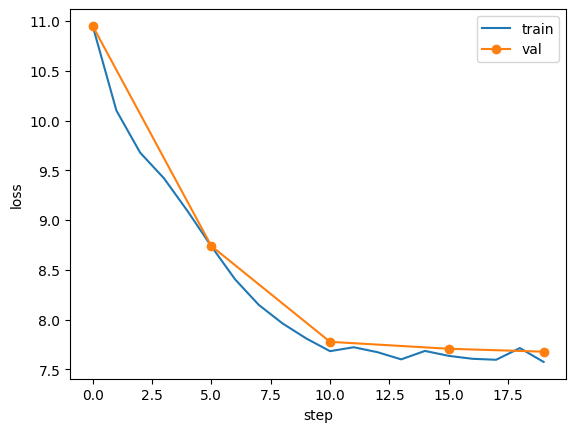

In [14]:
with open(log_path, "w") as f:
    json.dump(log, f)

plt.plot([r[0] for r in log["train"]], [r[1] for r in log["train"]], label="train")
plt.plot([v[0] for v in log["val"]], [v[1] for v in log["val"]], "o-", label="val")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.show()